In [1]:
import scanpy as sc
padata = sc.read("./h5ad/adata_fibroblast.h5ad")

batch2effect = {
    "H-nS01":"H-poor",
    "Q-nS01":"Q-poor",
    "Q-nS02":"Q-poor",
    "H-nS08":"H-good",
    "Q-nS03":"Q-good",
    "Q-nS04":"Q-good",
    "H-nS03":"H-good",
    "H-nS06":"H-good",
    "H-nS07":"H-good",
    "H-nS09":"H-poor",
    "H-nS10":"H-poor"
}
padata.obs["effect"]=[batch2effect[b] for b in padata.obs["batch"]]
padata = padata[padata.obs["celltype"]!="Vascular Smooth Muscle Cell"]

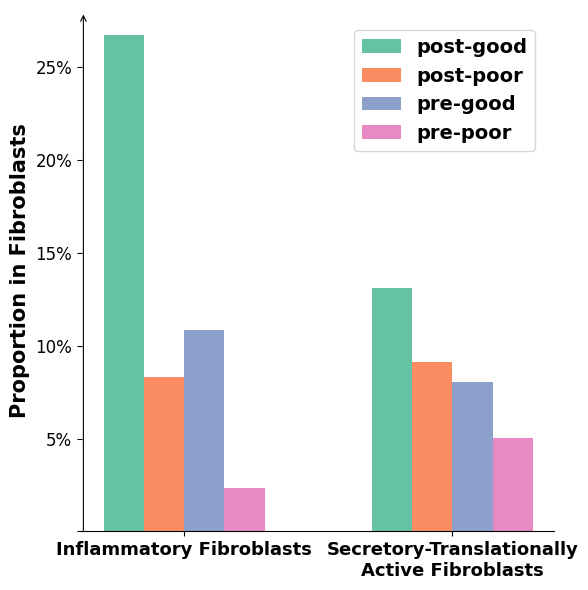

In [11]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import FuncFormatter
import numpy as np

# Data settings
groups = ['Inflammatory Fibroblasts', 'Secretory-Translationally\nActive Fibroblasts']
metrics = ['post-good', 'post-poor', 'pre-good', 'pre-poor']
colors = ["#66C2A5", "#FC8D62", "#8DA0CB", "#E78AC3"]
data = np.zeros((2,4))
for i,e in enumerate(['H-good', 'H-poor', 'Q-good', 'Q-poor']):
    for j,t in enumerate(['Inflammatory Fibroblast', 'Secretory-Translationally Active Fibroblast']):
        data[j,i] = padata[(padata.obs["celltype"]==t)&(padata.obs["effect"]==e)].n_obs/padata[padata.obs["effect"]==e].n_obs

x = np.arange(len(groups))
width = 0.15

fig, ax = plt.subplots(figsize=(6, 6))

for i in range(len(metrics)):
    ax.bar(x + i * width, data[:, i], width, label=metrics[i], color=colors[i])

ax.set_xticks(x + width * 1.5)
ax.set_xticklabels(groups, fontsize=13, fontweight="bold")

# Place the legend on the right side of the plot
ax.legend(title='', bbox_to_anchor=(0.98, 0.98), prop={'weight': 'bold', "size": 14})

ax.set_ylabel('Proportion in Fibroblasts', fontsize=15, fontweight='bold')

# Format y-axis tick labels as percentages
ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f'{int(y * 100)}%' if y != 0 else ""))

ax.tick_params(axis='y', labelsize=12)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_linewidth(0.8)
ax.spines['bottom'].set_color("black")

plt.grid(False)
plt.tight_layout()  # Automatically adjust subplot params to fill the figure area

# Get the actual left boundary of the y-axis dynamically (usually x=0)
x_arrow = ax.get_xlim()[0]

ax.annotate(
    '',
    xy=(-0.15, 0.28),
    xytext=(-0.15, -0.001),
    arrowprops=dict(arrowstyle='->', color='black', lw=0.8),
    xycoords='data',
    textcoords='data'
)
plt.show()

In [12]:
set(padata.obs["celltype"])

{'Inflammatory Fibroblast',
 'Inflammatory Myofibroblast',
 'Matrix-Remodeling Myofibroblast',
 'Matrix-Synthetic Fibroblast',
 'Perivascular Matrix Fibroblast',
 'Proliferating Fibroblast',
 'Secretory-Translationally Active Fibroblast',
 'Stress-Response Fibroblast'}